In [1]:
import os
import functools
import pathlib

import geopandas as gpd
import matplotlib.pyplot as plt
import movingpandas as mpd
import numpy as np
import pandas as pd
import scipy.optimize
import shapely

import importlib

import ship_action_modeller.ships
import python_vehicle_simulator.lib
import python_vehicle_simulator.vehicles as vehicles

import datetime

import warnings
# warnings.filterwarnings("ignore", category=pd.errors.SettingWithCopyWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import dask.dataframe as dd
import dask.distributed
import dask_geopandas as dgpd

from dask.diagnostics import ProgressBar

import ship_action_modeller.trajectory
import ship_action_modeller.currents

import traceback
from tqdm.auto import tqdm
%matplotlib inline
# %load_ext line_profiler

In [2]:
src_dir = pathlib.Path('~').expanduser() / 'data/ais'

In [3]:
cluster = dask.distributed.LocalCluster(n_workers=10, memory_limit="4GB")
cluster

LocalCluster(873aa42d, 'tcp://127.0.0.1:54719', workers=10, threads=10, memory=37.25 GiB)

2026-11-05 14:37:52,413 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 4edda33556db0898466b72fe578fed63 initialized by task ('shuffle-transfer-4edda33556db0898466b72fe578fed63', 2123) executed on worker tcp://127.0.0.1:54747
2026-11-05 15:29:55,251 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 4edda33556db0898466b72fe578fed63 deactivated due to stimulus 'task-erred-1793888995.1141949'
2026-11-05 15:29:55,258 - distributed.core - ERROR - Exception while handling op shuffle_restrict_task
Traceback (most recent call last):
  File "/Users/hemert/projects/scheepvaart-gedrag-ark/.venv/lib/python3.13/site-packages/distributed/core.py", line 796, in _handle_comm
    result = handler(**msg)
  File "/Users/hemert/projects/scheepvaart-gedrag-ark/.venv/lib/python3.13/site-packages/distributed/shuffle/_scheduler_plugin.py", line 152, in restrict_task
    shuffle = self.active_shuffles[id]
              ~~~~~~~~~~~~~~~~~~~~^^^^
KeyError: '4edda33556db0898466b72fe578fed63'


In [4]:
client = dask.distributed.Client(address=cluster)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 10
Total threads: 10,Total memory: 37.25 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:54719,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:54746,Total threads: 1
Dashboard: http://127.0.0.1:54749/status,Memory: 3.73 GiB
Nanny: tcp://127.0.0.1:54722,


In [8]:
mmsi_hash_example = '7873667eb228c4cb0932113a8a2f0c41'
ddf = dgpd.read_parquet(src_dir / 'ark_trajectory_points_no_stops',
        filters=[
            ("year", "==", 2026),
            ("month", "==", 9),
        ]
    )

hour = ddf["t"].dt.hour
ddf = ddf[(hour >= 18) | (hour < 6)]
ship_ddf = ddf[ddf['mmsi_hash'] == mmsi_hash_example]

traj_id = pd.unique(ship_ddf.compute().traj_id)[0]
ship_gdf = ship_ddf[ship_ddf['traj_id'] == traj_id].compute()

In [9]:
def inverse_ais(ship_gdf):
    trajectories = mpd.TrajectoryCollection(ship_gdf, traj_id_col='traj_id', t='t', obj_id_col='name')
    # trajectories = mpd.ObservationGapSplitter(trajectories).split(gap=datetime.timedelta(minutes=10))
    # trajectories = mpd.TemporalSplitter(trajectories).split(mode='h')

    trajectory = trajectories.trajectories[0]

    solutions = ship_action_modeller.trajectory.find_optimal_controls_for_trajectory(trajectory, tqdm_disable=True)
    solutions = pd.DataFrame(solutions)
    
    return solutions

def create_obs_action(df):
    traj_imitated = df['traj_imitation']
    traj_full = df['traj_full']
    traj_id = traj_full.df['traj_id'].iloc[0]

    first_obs = traj_imitated.df.iloc[0].copy()
    first_obs['traj_id'] = traj_id
    first_obs['timestamp'] = df['timestamp']

    last_obs = traj_full.df.iloc[-1]
    first_obs['last_lon'] = last_obs['longitude']  
    first_obs['last_lat'] = last_obs['latitude']

    first_obs["year"] = first_obs["timestamp"].year
    first_obs["month"] = first_obs["timestamp"].month
    first_obs["day"] = first_obs["timestamp"].day

    first_obs = first_obs.drop(['eta', 'nu'])

    # imitated_df = traj_imitated.df.apply(lambda traj: traj.iloc[0])
    return first_obs

In [10]:
ship_gdf['heading'] = ship_gdf['heading'].fillna(ship_gdf['direction'])
solution_df = inverse_ais(ship_gdf=ship_gdf)
meta_solution = dd.utils.make_meta(solution_df)

obs_df = solution_df.apply(create_obs_action, axis=1)
obs_gdf = gpd.GeoDataFrame(obs_df, geometry='geometry')
meta_obs = dd.utils.make_meta(obs_gdf)

In [11]:
ddf = ddf.set_index('traj_id', sorted=False, drop=True)
ddf['heading'] = ddf['heading'].fillna(ddf['direction'])
# ddf_sample = ddf_sample.persist()
solutions_ddf = ddf.groupby(['traj_id']).apply(inverse_ais, meta=meta_solution)
solutions_ddf = solutions_ddf.reset_index()

obs_ddf = solutions_ddf.apply(create_obs_action, axis=1, meta=meta_obs)
obs_gddf = dgpd.from_dask_dataframe(obs_ddf, geometry="geometry")

In [ ]:
for i in range(obs_ddf.npartitions):
    part = obs_ddf.partitions[i].compute()
    if "geometry" not in part.columns:
        print("BAD:", i, len(part), part.columns)
        if i > 10:
            break

In [20]:
obs_gdf.columns

Index(['x', 'y', 'timestamp', 'u', 'v', 'rudder_angle', 'tau_X',
       'course_over_ground_rad', 'psi', 'heading', 'cog', 'velocity',
       'geometry', 'traj_id', 'speed', 'direction', 'iteration', 'V_current',
       'beta_current', 'last_lon', 'last_lat', 'year', 'month', 'day'],
      dtype='str')

In [18]:
print(obs_ddf._meta.columns)
print(obs_ddf._meta.dtypes)
print(obs_ddf.partitions[0].compute().columns)

Index(['x', 'y', 'timestamp', 'u', 'v', 'rudder_angle', 'tau_X',
       'course_over_ground_rad', 'psi', 'heading', 'cog', 'velocity',
       'geometry', 'traj_id', 'speed', 'direction', 'iteration', 'V_current',
       'beta_current', 'last_lon', 'last_lat', 'year', 'month', 'day'],
      dtype='str')
x                                float64
y                                float64
timestamp                 datetime64[us]
u                                float64
v                                float64
rudder_angle                     float64
tau_X                            float64
course_over_ground_rad           float64
psi                              float64
heading                          float64
cog                              float64
velocity                         float64
geometry                        geometry
traj_id                              str
speed                            float64
direction                        float64
iteration                          int64

In [12]:
obs_gddf.to_parquet(src_dir / 'ark-trajectories-with-actions-no-stops', partition_on=["year", "month", "day"])

2026-11-05 15:29:55,114 - distributed.worker - ERROR - Compute Failed
Key:       ('operation-10a4e9a4c04fc933a0102a2d7dded7a0', 907)
State:     executing
Task:  <Task ('operation-10a4e9a4c04fc933a0102a2d7dded7a0', 907) apply_and_enforce(..., ...)>
Exception: "IndexError('list index out of range')"
Traceback: '  File "/Users/hemert/projects/scheepvaart-gedrag-ark/.venv/lib/python3.13/site-packages/dask/dataframe/core.py", line 99, in apply_and_enforce\n    df = func(*args, **kwargs)\n  File "/Users/hemert/projects/scheepvaart-gedrag-ark/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_groupby.py", line 1199, in operation\n    return dask_func(\n        frame,\n    ...<6 lines>...\n        **kwargs,\n    )\n  File "/Users/hemert/projects/scheepvaart-gedrag-ark/.venv/lib/python3.13/site-packages/dask/dataframe/dask_expr/_groupby.py", line 1235, in groupby_slice_apply\n    return _groupby_slice_apply(\n        df,\n    ...<7 lines>...\n        **kwargs,\n    )\n  File "/Users/h

IndexError: list index out of range

In [16]:
print(type(obs_ddf))
print(type(obs_ddf._meta))
obs_ddf.geometry.dtype

<class 'dask.dataframe.dask_expr._collection.DataFrame'>
<class 'pandas.DataFrame'>


dtype('O')

In [20]:
type(ddf)

dask_geopandas.expr.GeoDataFrame

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

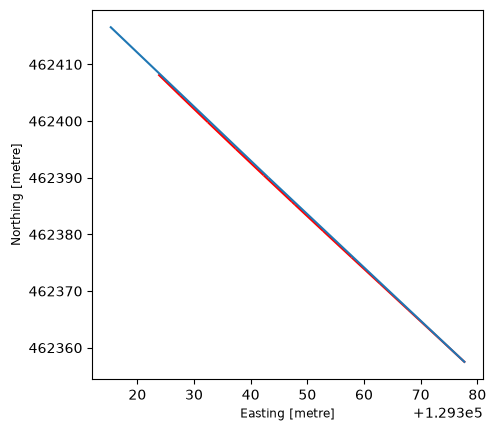

In [28]:
i = -1
fig, ax = plt.subplots()
solution_df.iloc[i]['traj_imitation'].plot(ax=ax, color='red')
solution_df.iloc[i]['traj_segment'].plot(ax=ax)

In [12]:
ship_gdf

,t,timestamp_recv,mmsi_hash,longitude,latitude,length,beam,objecttype,cog,sog,...,geometry,traj_id,ship_length,acceleration,angular_difference,direction,speed,year,month,day
53689,2026-07-03 06:26:11.215,2026-07-03 06:26:11.215000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08165,52.079138,70.0,10.0,VESA,334.0,9.8,...,POINT (134054.141 454584.485),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.000000,0.000000,340.572909,4.597575,2026,7,3
53690,2026-07-03 06:26:20.518,2026-07-03 06:26:20.518000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08144,52.079500,70.0,10.0,VESA,343.0,8.5,...,POINT (134039.915 454624.821),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.000000,0.000000,340.572909,4.597575,2026,7,3
53691,2026-07-03 06:26:29.745,2026-07-03 06:26:29.745000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08129,52.079855,70.0,10.0,VESA,343.9,8.5,...,POINT (134029.799 454664.361),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.018890,5.076087,345.648996,4.423275,2026,7,3
53692,2026-07-03 06:26:40.157,2026-07-03 06:26:40.157000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08113,52.080243,70.0,10.0,VESA,345.6,8.6,...,POINT (134019.013 454707.576),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.013975,0.336781,345.985777,4.277769,2026,7,3
53693,2026-07-03 06:26:50.891,2026-07-03 06:26:50.891000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08097,52.080663,70.0,10.0,VESA,347.3,8.5,...,POINT (134008.242 454754.351),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.018063,1.046830,347.032608,4.471659,2026,7,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53909,2026-07-03 07:03:10.297,2026-07-03 07:03:10.297000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.01332,52.148540,70.0,10.0,VESA,312.7,8.3,...,POINT (129409.866 462327.962),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.071653,0.190291,313.630559,4.009540,2026,7,3
53910,2026-07-03 07:03:19.837,2026-07-03 07:03:19.837000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.01285,52.148803,70.0,10.0,VESA,312.9,8.4,...,POINT (129377.848 462357.389),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.057526,1.044885,312.585674,4.558333,2026,7,3
53911,2026-07-03 07:03:30.375,2026-07-03 07:03:30.375000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.01234,52.149095,70.0,10.0,VESA,312.6,8.4,...,POINT (129343.11 462390.057),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.003151,0.654942,313.240616,4.525130,2026,7,3
53912,2026-07-03 07:03:39.907,2026-07-03 07:03:39.907000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.01193,52.149333,70.0,10.0,VESA,312.6,8.4,...,POINT (129315.185 462416.681),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.050082,0.394196,313.634812,4.047753,2026,7,3


In [29]:
ddf.head(npartitions=100)

,timestamp_recv,mmsi_hash,longitude,latitude,length,beam,objecttype,cog,sog,heading,...,geom,traj_id,ship_length,acceleration,angular_difference,direction,speed,year,month,day
0,2026-07-01 13:06:29.794000+00:00,d3e455677244ec8ab40c7c3c8e56552e,5.08169,52.079108,60.0,10.0,VESA,334.5,7.2,NaN,...,POINT (134056.869 454581.136),d3e455677244ec8ab40c7c3c8e56552e_0,60.0,0.000000,0.000000,343.078338,4.452027,2026,7,1
1,2026-07-01 13:06:40.230000+00:00,d3e455677244ec8ab40c7c3c8e56552e,5.08149,52.079507,60.0,10.0,VESA,343.7,8.1,NaN,...,POINT (134043.345 454625.586),d3e455677244ec8ab40c7c3c8e56552e_0,60.0,0.000000,0.000000,343.078338,4.452027,2026,7,1
2,2026-07-01 13:06:48.652000+00:00,d3e455677244ec8ab40c7c3c8e56552e,5.08137,52.079800,60.0,10.0,VESA,345.4,8.1,NaN,...,POINT (134035.257 454658.219),d3e455677244ec8ab40c7c3c8e56552e_0,60.0,-0.054619,3.000524,346.078862,3.992024,2026,7,1
3,2026-07-01 13:06:59.651000+00:00,d3e455677244ec8ab40c7c3c8e56552e,5.08120,52.080202,60.0,10.0,VESA,345.7,8.1,NaN,...,POINT (134023.792 454702.994),d3e455677244ec8ab40c7c3c8e56552e_0,60.0,0.019104,0.441283,345.637579,4.202151,2026,7,1
4,2026-07-01 13:07:08.994000+00:00,d3e455677244ec8ab40c7c3c8e56552e,5.08108,52.080530,60.0,10.0,VESA,346.3,8.1,NaN,...,POINT (134015.72 454739.521),d3e455677244ec8ab40c7c3c8e56552e_0,60.0,-0.021217,1.901138,347.538717,4.003923,2026,7,1


In [18]:
solution_df

,timestamp,rudder_angle,tau_X,optimization_error,traj_full,traj_segment,traj_imitation,iteration
0,2026-07-03 06:26:11.215,0.008625,38688.425456,2.154139,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,0
1,2026-07-03 06:26:41.215,-0.065037,40730.147309,0.242152,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,1
2,2026-07-03 06:27:11.215,0.014640,85739.072275,1.797462,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,2
3,2026-07-03 06:27:41.215,0.277986,66298.933948,0.377118,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,3
4,2026-07-03 06:28:11.215,0.004171,87734.075548,1.540015,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,4
...,...,...,...,...,...,...,...,...
70,2026-07-03 07:01:11.215,0.070473,83316.044799,1.369650,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,70
71,2026-07-03 07:01:41.215,0.040074,84108.098618,2.442225,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,71
72,2026-07-03 07:02:11.215,-0.095878,76042.374813,1.146707,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,72
73,2026-07-03 07:02:41.215,-0.114718,83119.389901,2.368490,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0 ...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,Trajectory ab9a18bcc506bcd3b94fe0c52b3e0e90_0_...,73


In [21]:
solution_df['traj_imitation'].iloc[0].to_point_gdf()['traj_id'].iloc[0]

'ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 06:26:11.215000_logbook'

In [22]:
solution_df['traj_segment'].iloc[0].to_point_gdf()['traj_id'].iloc[0]

'ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 06:26:11.215000'

In [23]:
solution_df['traj_full'].iloc[0].to_point_gdf()['traj_id'].iloc[0]

'ab9a18bcc506bcd3b94fe0c52b3e0e90_0'

In [24]:
solution_df['traj_imitation'].iloc[0].to_point_gdf()

,x,y,eta,nu,timestamp,u,v,rudder_angle,tau_X,course_over_ground_rad,...,heading,cog,velocity,geometry,traj_id,speed,direction,iteration,V_current,beta_current
date,,,,,,,,,,,,,,,,,,,,,
2026-07-03 06:26:11.215000,134054.140727,454584.485297,"[454584.4852966335, 134054.1407272127, 0.0, 0....","[5.008418678832549, -0.5770941304232424, 0.0, ...",0.000000,-1.665835,4.723267,0.008625,38688.425456,-0.453786,...,340.572909,-26.000000,5.008419,POINT (134054.141 454584.485),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.938676,334.296735,0,0,0
2026-07-03 06:26:12.603460,134051.166708,454590.663952,"[454596.87086930993, 134048.25967754042, 0.0, ...","[4.909076395550973, -0.5399009119403587, 0.0, ...",1.388460,-1.610786,4.637284,0.008625,38688.425456,-0.443857,...,341.340117,-25.431123,4.909076,POINT (134051.167 454590.664),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.938676,334.296735,0,0,0
2026-07-03 06:26:14.020844,134048.259678,454596.870869,"[454603.1185592287, 134045.44944028973, 0.0, 0...","[4.809661184106865, -0.5005298384707176, 0.0, ...",2.805844,-1.538850,4.556839,0.008625,38688.425456,-0.429371,...,341.997901,-24.601131,4.809661,POINT (134048.26 454596.871),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.835635,334.903804,0,0,0
2026-07-03 06:26:15.468430,134045.449440,454603.118559,"[454609.41439492855, 134042.75659580252, 0.0, ...","[4.710193418940036, -0.4583970029536797, 0.0, ...",4.253430,-1.455694,4.479607,0.008625,38688.425456,-0.411211,...,342.775069,-23.560632,4.710193,POINT (134045.449 454603.119),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.732448,335.781584,0,0,0
2026-07-03 06:26:16.947581,134042.756596,454609.414395,"[454615.76209950534, 134040.19661371867, 0.0, ...","[4.610655516559529, -0.41596663893592345, 0.0,...",5.732581,-1.365324,4.403866,0.008625,38688.425456,-0.390607,...,343.632200,-22.380117,4.610656,POINT (134042.757 454609.414),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.629379,336.842715,0,0,0
2026-07-03 06:26:18.459662,134040.196614,454615.762100,"[454622.1622665451, 134037.77945717765, 0.0, 0...","[4.511053682782803, -0.3739615287264102, 0.0, ...",7.244662,-1.271225,4.328232,0.008625,38688.425456,-0.368382,...,344.538197,-21.106723,4.511054,POINT (134040.197 454615.762),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.526528,338.036146,0,0,0
2026-07-03 06:26:20.006101,134037.779457,454622.162267,"[454624.27900864807, 134037.02349138167, 0.0, ...","[4.411388616269326, -0.333419878416838, 0.0, 0...",8.791101,-1.176058,4.251733,0.008625,38688.425456,-0.345298,...,344.838279,-19.784092,4.411389,POINT (134037.779 454622.162),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.423972,339.309911,0,0,0
2026-07-03 06:26:20.518000,134037.023491,454624.279009,"[454630.7457331283, 134034.80343595205, 0.0, 0...","[4.379126760442513, -0.32094491982439677, 0.0,...",9.303000,-1.145336,4.226696,0.008625,38688.425456,-0.337781,...,345.767672,-19.353418,4.379127,POINT (134037.023 454624.279),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.390873,340.346501,0,0,0
2026-07-03 06:26:22.112216,134034.803436,454630.745733,"[454637.25871439785, 134032.73401663877, 0.0, ...","[4.279387884556125, -0.28317544649867016, 0.0,...",10.897216,-1.052106,4.148040,0.008625,38688.425456,-0.314477,...,346.693889,-18.018182,4.279388,POINT (134034.803 454630.746),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.288748,341.052425,0,0,0


In [27]:
solution_df['traj_imitation'].iloc[0].df

,x,y,eta,nu,timestamp,u,v,rudder_angle,tau_X,course_over_ground_rad,...,heading,cog,velocity,geometry,traj_id,speed,direction,iteration,V_current,beta_current
date,,,,,,,,,,,,,,,,,,,,,
2026-07-03 06:26:11.215000,134054.140727,454584.485297,"[454584.4852966335, 134054.1407272127, 0.0, 0....","[5.008418678832549, -0.5770941304232424, 0.0, ...",0.000000,-1.665835,4.723267,0.008625,38688.425456,-0.453786,...,340.572909,-26.000000,5.008419,POINT (134054.141 454584.485),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.938676,334.296735,0,0,0
2026-07-03 06:26:12.603460,134051.166708,454590.663952,"[454596.87086930993, 134048.25967754042, 0.0, ...","[4.909076395550973, -0.5399009119403587, 0.0, ...",1.388460,-1.610786,4.637284,0.008625,38688.425456,-0.443857,...,341.340117,-25.431123,4.909076,POINT (134051.167 454590.664),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.938676,334.296735,0,0,0
2026-07-03 06:26:14.020844,134048.259678,454596.870869,"[454603.1185592287, 134045.44944028973, 0.0, 0...","[4.809661184106865, -0.5005298384707176, 0.0, ...",2.805844,-1.538850,4.556839,0.008625,38688.425456,-0.429371,...,341.997901,-24.601131,4.809661,POINT (134048.26 454596.871),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.835635,334.903804,0,0,0
2026-07-03 06:26:15.468430,134045.449440,454603.118559,"[454609.41439492855, 134042.75659580252, 0.0, ...","[4.710193418940036, -0.4583970029536797, 0.0, ...",4.253430,-1.455694,4.479607,0.008625,38688.425456,-0.411211,...,342.775069,-23.560632,4.710193,POINT (134045.449 454603.119),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.732448,335.781584,0,0,0
2026-07-03 06:26:16.947581,134042.756596,454609.414395,"[454615.76209950534, 134040.19661371867, 0.0, ...","[4.610655516559529, -0.41596663893592345, 0.0,...",5.732581,-1.365324,4.403866,0.008625,38688.425456,-0.390607,...,343.632200,-22.380117,4.610656,POINT (134042.757 454609.414),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.629379,336.842715,0,0,0
2026-07-03 06:26:18.459662,134040.196614,454615.762100,"[454622.1622665451, 134037.77945717765, 0.0, 0...","[4.511053682782803, -0.3739615287264102, 0.0, ...",7.244662,-1.271225,4.328232,0.008625,38688.425456,-0.368382,...,344.538197,-21.106723,4.511054,POINT (134040.197 454615.762),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.526528,338.036146,0,0,0
2026-07-03 06:26:20.006101,134037.779457,454622.162267,"[454624.27900864807, 134037.02349138167, 0.0, ...","[4.411388616269326, -0.333419878416838, 0.0, 0...",8.791101,-1.176058,4.251733,0.008625,38688.425456,-0.345298,...,344.838279,-19.784092,4.411389,POINT (134037.779 454622.162),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.423972,339.309911,0,0,0
2026-07-03 06:26:20.518000,134037.023491,454624.279009,"[454630.7457331283, 134034.80343595205, 0.0, 0...","[4.379126760442513, -0.32094491982439677, 0.0,...",9.303000,-1.145336,4.226696,0.008625,38688.425456,-0.337781,...,345.767672,-19.353418,4.379127,POINT (134037.023 454624.279),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.390873,340.346501,0,0,0
2026-07-03 06:26:22.112216,134034.803436,454630.745733,"[454637.25871439785, 134032.73401663877, 0.0, ...","[4.279387884556125, -0.28317544649867016, 0.0,...",10.897216,-1.052106,4.148040,0.008625,38688.425456,-0.314477,...,346.693889,-18.018182,4.279388,POINT (134034.803 454630.746),ab9a18bcc506bcd3b94fe0c52b3e0e90_0_2026-07-03 ...,4.288748,341.052425,0,0,0


In [30]:
solution_df['traj_full'].iloc[0].df

,timestamp_recv,mmsi_hash,longitude,latitude,length,beam,objecttype,cog,sog,heading,...,geometry,traj_id,ship_length,acceleration,angular_difference,direction,speed,year,month,day
t,,,,,,,,,,,,,,,,,,,,,
2026-07-03 06:26:11.215,2026-07-03 06:26:11.215000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08165,52.079138,70.0,10.0,VESA,334.0,9.8,340.572909,...,POINT (134054.141 454584.485),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.000000,0.000000,340.572909,4.597575,2026,7,3
2026-07-03 06:26:20.518,2026-07-03 06:26:20.518000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08144,52.079500,70.0,10.0,VESA,343.0,8.5,340.572909,...,POINT (134039.915 454624.821),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.000000,0.000000,340.572909,4.597575,2026,7,3
2026-07-03 06:26:29.745,2026-07-03 06:26:29.745000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08129,52.079855,70.0,10.0,VESA,343.9,8.5,345.648996,...,POINT (134029.799 454664.361),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.018890,5.076087,345.648996,4.423275,2026,7,3
2026-07-03 06:26:40.157,2026-07-03 06:26:40.157000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08113,52.080243,70.0,10.0,VESA,345.6,8.6,345.985777,...,POINT (134019.013 454707.576),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.013975,0.336781,345.985777,4.277769,2026,7,3
2026-07-03 06:26:50.891,2026-07-03 06:26:50.891000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.08097,52.080663,70.0,10.0,VESA,347.3,8.5,347.032608,...,POINT (134008.242 454754.351),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.018063,1.046830,347.032608,4.471659,2026,7,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-03 07:03:10.297,2026-07-03 07:03:10.297000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.01332,52.148540,70.0,10.0,VESA,312.7,8.3,313.630559,...,POINT (129409.866 462327.962),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.071653,0.190291,313.630559,4.009540,2026,7,3
2026-07-03 07:03:19.837,2026-07-03 07:03:19.837000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.01285,52.148803,70.0,10.0,VESA,312.9,8.4,312.585674,...,POINT (129377.848 462357.389),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,0.057526,1.044885,312.585674,4.558333,2026,7,3
2026-07-03 07:03:30.375,2026-07-03 07:03:30.375000+00:00,ab9a18bcc506bcd3b94fe0c52b3e0e90,5.01234,52.149095,70.0,10.0,VESA,312.6,8.4,313.240616,...,POINT (129343.11 462390.057),ab9a18bcc506bcd3b94fe0c52b3e0e90_0,70.0,-0.003151,0.654942,313.240616,4.525130,2026,7,3
